# 実験2 (ex002): 非凸モデル (CompactCNN) における FedSSO × MoQ ファミリー 10シード比較実験

本実験では、非凸目的関数（論文 Table 1 準拠 `CompactCNN`, パラメータ数 $d = 6,230$）のNon-IID連合学習（MNIST, $N = 20, \beta = 0.1$）において、原論文の **FedSSO** および **FedSSO-LBFGS** に対し、慣性付準ニュートン法（**NAQ, MoQ, AdaNAQ, AdaMoQ, LNAQ, LMoQ, MLNAQ, MLMoQ**）と1次ベースライン（**FedAvg**）を **10種類の乱数シード** で比較評価する。

## 評価観点
1. **GPU並列 `groups=N` バッチCNN SGD と逐次実装の数値等価性検証**
2. **10シード統計評価（Ave / Med / Best / Worst / Std）**：非凸損失曲面における到達精度・安定性比較
3. **通信効率比較**：NAQ系（$2n_c$/反復）と MoQ系（線形外挿勾配により $n_c$/反復）の累積通信ラウンド数および目標精度到達総通信バイト数（$n_c = 49,840\,\mathrm{B}$）

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from model import CompactCNN
from utils import (
    DEFAULT_SEEDS,
    setup_japanese_matplotlib,
    load_and_partition_mnist_2d,
    verify_batched_cnn_equivalence,
    run_multiseed_cnn,
    plot_filtered_cnn_results,
)

setup_japanese_matplotlib()
os.makedirs("../report/img", exist_ok=True)
os.makedirs("../datasets", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
cnn_tmp = CompactCNN()
n_params = sum(p.numel() for p in cnn_tmp.parameters())
print(f"CompactCNN 総パラメータ数: {n_params} (1通信ラウンド基準通信量 nc = {n_params * 8} Bytes)")
print(f"実験シード (10種類): {DEFAULT_SEEDS}")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)
CompactCNN 総パラメータ数: 6230 (1通信ラウンド基準通信量 nc = 49840 Bytes)
実験シード (10種類): [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]


In [2]:
# Non-IID MNIST (2D画像) データ分割の読み込みと GPU バッチCNN等価性検証
clients_data, packed_clients, X_train, y_train, X_test, y_test = load_and_partition_mnist_2d(
    data_dir="../datasets", num_clients=20, beta=0.1, train_ratio=0.75, seed=42, device=device
)
print(f"全体訓練サンプル数: {len(X_train)}, 全体テストサンプル数: {len(X_test)}")
max_diff = verify_batched_cnn_equivalence(clients_data, packed_clients, tau=5, batch_size=100, lr=0.07, seed=42, device=device)
print(f"逐次クライアントCNN SGD vs GPUバッチ並列CNN SGD 最大絶対誤差: {max_diff:.3e}")
assert max_diff < 1e-5, f"数値等価性誤差が閾値を超過しました: {max_diff}"

全体訓練サンプル数: 52492, 全体テストサンプル数: 17508
逐次クライアントCNN SGD vs GPUバッチ並列CNN SGD 最大絶対誤差: 2.980e-08


In [3]:
# 全11手法の設定（FedSSOの曲率クリッピング lam=1e-4, Lam=9999, R=200 を統一適用）
algo_configs = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.3},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.07, "eta": 0.3},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.07, "eta": 0.3, "mu": 0.25},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.07, "eta": 0.3, "mu": 0.25},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.07, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.07, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.07, "eta": 0.3, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.07, "eta": 0.3, "m_size": 10, "max_mu": 0.30},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.07, "eta": 0.3, "m_size": 10, "max_mu": 0.30},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.07, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.07, "eta": 0.3, "max_mu": 0.30},
]

summary_df, per_seed_df, curves_dict = run_multiseed_cnn(
    algo_configs=algo_configs,
    packed_clients=packed_clients,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seeds=DEFAULT_SEEDS,
    rounds=200,
    tau=5,
    batch_size=100,
    targets=(0.80, 0.90, 0.95, 0.97),
    param_dim=6230,
    save_log_dir="../datasets/ex002_cnn_logs",
    history_csv_path="../datasets/ex002_cnn_history.csv",
)

summary_df.to_csv("../datasets/ex002_cnn_summary.csv", index=False)
per_seed_df.to_csv("../datasets/ex002_cnn_per_seed.csv", index=False)
print("=== 10シード統計サマリー (CompactCNN, 200ラウンド) ===")
disp_cols = ["Algorithm", "Acc_Ave", "Acc_Med", "Acc_Best", "Acc_Worst", "Acc_Std", "Loss_Ave", "Loss_Best", "Loss_Worst", "Clip_Ave", "Reset_Ave", "Server_Time_ms", "Server_Mem_MB"]
summary_df[disp_cols]

=== 10シード統計サマリー (CompactCNN, 200ラウンド) ===


CNN Multi-Seed Experiment: 100%|##########| 110/110 [08:55<00:00,  4.87s/it, acc=0.9212, algo=FedSSO-MLMoQ, seed=51]


,Algorithm,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,Loss_Ave,Loss_Best,Loss_Worst,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB
0,FedAvg,0.957654,0.960133,0.976525,0.928376,0.016841,0.135156,0.065695,0.305894,0.0,0.0,0.009010,0.023766
1,FedSSO,0.980038,0.981951,0.984236,0.965958,0.004995,0.039779,0.021391,0.100314,1.3,1.7,4.990783,148.154526
2,FedSSO-NAQ,0.981814,0.982122,0.984407,0.976525,0.002021,0.032050,0.023631,0.046347,1.0,1.3,4.931559,148.202057
3,FedSSO-MoQ,0.980723,0.981608,0.984293,0.972013,0.003285,0.038971,0.022120,0.072758,1.7,1.7,5.030814,148.225822
4,FedSSO-AdaNAQ,0.964051,0.982180,0.983836,0.801634,0.054150,0.116632,0.025053,0.878265,0.9,1.4,4.939888,148.202057
5,FedSSO-AdaMoQ,0.976588,0.976868,0.982979,0.967215,0.005005,0.056601,0.028493,0.086091,1.9,2.3,4.993113,148.225822
6,FedSSO-LBFGS,0.970345,0.970442,0.977496,0.962246,0.003971,0.083708,0.060288,0.117346,13.7,1.8,1.395939,0.570374
7,FedSSO-LNAQ,0.969814,0.970585,0.973498,0.962132,0.003226,0.087340,0.075688,0.107515,17.7,1.8,1.317156,0.617905
8,FedSSO-LMoQ,0.966929,0.969128,0.972127,0.946767,0.006977,0.098569,0.075330,0.185704,15.8,2.3,1.560464,0.641670
9,FedSSO-MLNAQ,0.905666,0.907985,0.941912,0.817055,0.033387,0.328608,0.187668,0.661426,153.2,1.1,0.642114,0.190125


In [4]:
print("=== 目標精度到達反復数・累積通信ラウンド数・総通信量 (CompactCNN) ===")
comm_cols = ["Algorithm", "Comm_Per_Iter", "Iter@0.80_Ave", "Comm@0.80_Ave", "Iter@0.90_Ave", "Comm@0.90_Ave", "Bytes@0.90_Ave", "Reach_0.90_Rate", "Iter@0.95_Ave", "Comm@0.95_Ave", "Reach_0.95_Rate", "Iter@0.97_Ave", "Reach_0.97_Rate"]
summary_df[comm_cols]

=== 目標精度到達反復数・累積通信ラウンド数・総通信量 (CompactCNN) ===


,Algorithm,Comm_Per_Iter,Iter@0.80_Ave,Comm@0.80_Ave,Iter@0.90_Ave,Comm@0.90_Ave,Bytes@0.90_Ave,Reach_0.90_Rate,Iter@0.95_Ave,Comm@0.95_Ave,Reach_0.95_Rate,Iter@0.97_Ave,Reach_0.97_Rate
0,FedAvg,1.000,26.0,26.0,44.500000,44.500000,2.217880e+06,1.0,97.5,97.5,1.0,142.250000,0.4
1,FedSSO,1.000,13.6,13.6,19.700000,19.700000,9.818480e+05,1.0,34.5,34.5,1.0,61.700000,1.0
2,FedSSO-NAQ,1.995,11.4,21.8,17.200000,33.400000,1.664656e+06,1.0,29.3,57.6,1.0,54.100000,1.0
3,FedSSO-MoQ,1.000,17.2,17.2,25.600000,25.600000,1.275904e+06,1.0,43.1,43.1,1.0,78.400000,1.0
4,FedSSO-AdaNAQ,1.995,11.6,22.2,16.800000,32.600000,1.624784e+06,1.0,29.3,57.6,1.0,53.400000,1.0
5,FedSSO-AdaMoQ,1.000,20.1,20.1,27.800000,27.800000,1.385552e+06,1.0,44.5,44.5,1.0,84.000000,1.0
6,FedSSO-LBFGS,1.000,19.6,19.6,29.800000,29.800000,1.485232e+06,1.0,61.7,61.7,1.0,156.428571,0.7
7,FedSSO-LNAQ,1.995,21.4,41.8,31.600000,62.200000,3.100048e+06,1.0,69.3,137.6,1.0,159.333333,0.6
8,FedSSO-LMoQ,1.000,22.8,22.8,35.300000,35.300000,1.759352e+06,1.0,76.2,76.2,1.0,178.500000,0.4
9,FedSSO-MLNAQ,1.995,56.0,111.0,100.500000,200.000000,9.968000e+06,0.8,NaN,NaN,0.0,NaN,0.0


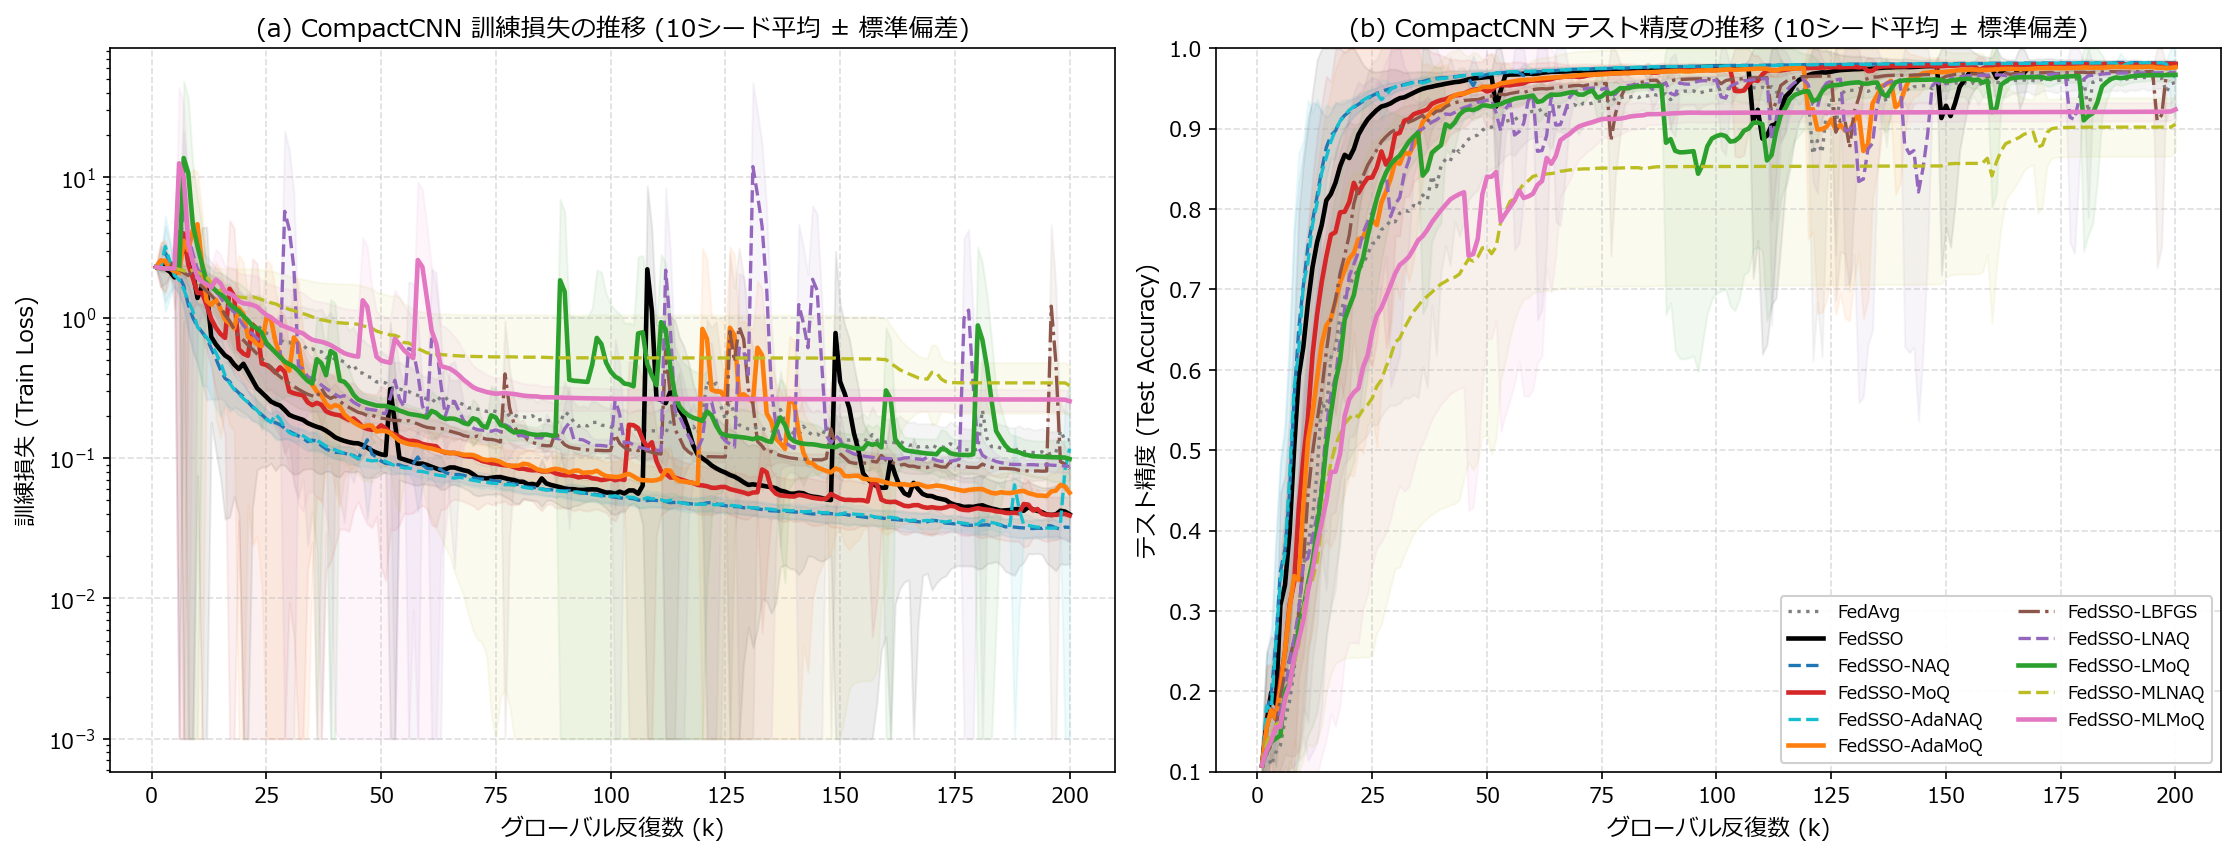

In [5]:
# 図1: CompactCNN 10シード平均学習曲線 (訓練損失 & テスト精度)
rounds_x = np.arange(1, 201)
color_map = {
    "FedAvg": "#7f7f7f",
    "FedSSO": "#000000",
    "FedSSO-NAQ": "#1f77b4",
    "FedSSO-MoQ": "#d62728",
    "FedSSO-AdaNAQ": "#17becf",
    "FedSSO-AdaMoQ": "#ff7f0e",
    "FedSSO-LBFGS": "#8c564b",
    "FedSSO-LNAQ": "#9467bd",
    "FedSSO-LMoQ": "#2ca02c",
    "FedSSO-MLNAQ": "#bcbd22",
    "FedSSO-MLMoQ": "#e377c2",
}
ls_map = {
    "FedAvg": ":",
    "FedSSO": "-",
    "FedSSO-NAQ": "--",
    "FedSSO-MoQ": "-",
    "FedSSO-AdaNAQ": "--",
    "FedSSO-AdaMoQ": "-",
    "FedSSO-LBFGS": "-.",
    "FedSSO-LNAQ": "--",
    "FedSSO-LMoQ": "-",
    "FedSSO-MLNAQ": "--",
    "FedSSO-MLMoQ": "-",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for name, d_c in curves_dict.items():
    c = color_map[name]
    ls = ls_map[name]
    lw = 2.2 if "MoQ" in name or name == "FedSSO" else 1.6
    axes[0].plot(rounds_x, d_c["loss_mean"], label=name, color=c, linestyle=ls, linewidth=lw)
    axes[0].fill_between(rounds_x, np.maximum(d_c["loss_mean"] - d_c["loss_std"], 1e-3), d_c["loss_mean"] + d_c["loss_std"], color=c, alpha=0.07)
    axes[1].plot(rounds_x, d_c["acc_mean"], label=name, color=c, linestyle=ls, linewidth=lw)
    axes[1].fill_between(rounds_x, np.maximum(d_c["acc_mean"] - d_c["acc_std"], 0.0), np.minimum(d_c["acc_mean"] + d_c["acc_std"], 1.0), color=c, alpha=0.07)

axes[0].set_title("(a) CompactCNN 訓練損失の推移 (10シード平均 ± 標準偏差)", fontsize=12)
axes[0].set_xlabel("グローバル反復数 (k)", fontsize=11)
axes[0].set_ylabel("訓練損失 (Train Loss)", fontsize=11)
axes[0].set_yscale("log")
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].set_title("(b) CompactCNN テスト精度の推移 (10シード平均 ± 標準偏差)", fontsize=12)
axes[1].set_xlabel("グローバル反復数 (k)", fontsize=11)
axes[1].set_ylabel("テスト精度 (Test Accuracy)", fontsize=11)
axes[1].set_ylim(0.10, 1.00)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(loc="lower right", fontsize=8.5, ncol=2, framealpha=0.92)

plt.tight_layout()
plt.savefig("../report/img/ex002_cnn_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

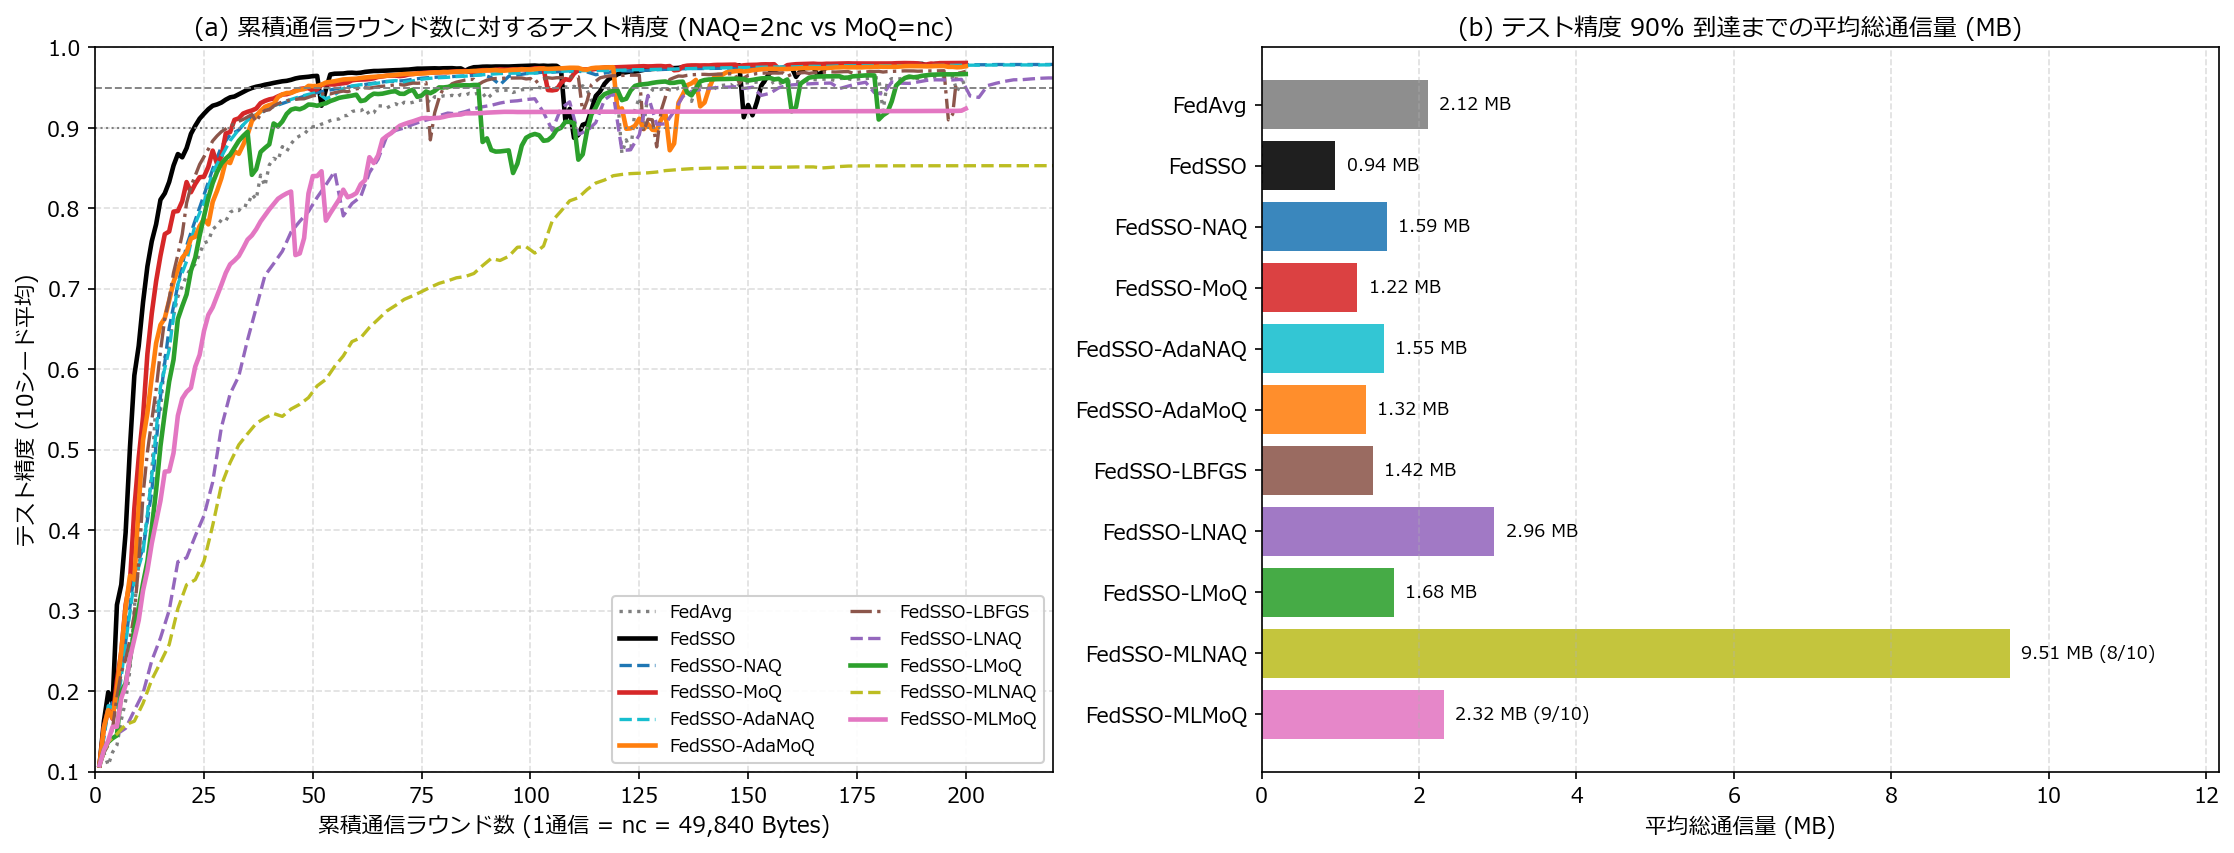

In [6]:
# 図2: 累積通信ラウンド数に対するテスト精度と目標精度 90% 到達総通信量比較
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for name, d_c in curves_dict.items():
    c = color_map[name]
    ls = ls_map[name]
    lw = 2.2 if "MoQ" in name or name == "FedSSO" else 1.6
    axes[0].plot(d_c["comm_mean"], d_c["acc_mean"], label=name, color=c, linestyle=ls, linewidth=lw)

axes[0].set_title("(a) 累積通信ラウンド数に対するテスト精度 (NAQ=2nc vs MoQ=nc)", fontsize=11.5)
axes[0].set_xlabel("累積通信ラウンド数 (1通信 = nc = 49,840 Bytes)", fontsize=10.5)
axes[0].set_ylabel("テスト精度 (10シード平均)", fontsize=10.5)
axes[0].set_xlim(0, 220)
axes[0].set_ylim(0.10, 1.00)
axes[0].axhline(0.90, color="gray", linestyle=":", linewidth=1.0)
axes[0].axhline(0.95, color="gray", linestyle="--", linewidth=0.9)
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(loc="lower right", fontsize=8.5, ncol=2, framealpha=0.92)

plot_df = summary_df.copy()
plot_df["MB_090"] = plot_df["Bytes@0.90_Ave"] / (1024.0 ** 2)
bars = axes[1].barh(plot_df["Algorithm"][::-1], plot_df["MB_090"][::-1].fillna(0.0),
                    color=[color_map[a] for a in plot_df["Algorithm"][::-1]], alpha=0.88)
max_mb = plot_df["MB_090"].dropna().max()
for bar, val, rate in zip(bars, plot_df["MB_090"][::-1], plot_df["Reach_0.90_Rate"][::-1]):
    if np.isfinite(val):
        lbl = f"{val:.2f} MB" if rate == 1.0 else f"{val:.2f} MB ({int(rate*10)}/10)"
        axes[1].text(val + max_mb * 0.015, bar.get_y() + bar.get_height() / 2, lbl, va="center", fontsize=8.5)
    else:
        axes[1].text(max_mb * 0.02, bar.get_y() + bar.get_height() / 2, "未到達", va="center", fontsize=8.5, color="red")
axes[1].set_title("(b) テスト精度 90% 到達までの平均総通信量 (MB)", fontsize=11.5)
axes[1].set_xlabel("平均総通信量 (MB)", fontsize=10.5)
axes[1].set_xlim(0, max_mb * 1.28)
axes[1].grid(True, axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("../report/img/ex002_cnn_comm_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

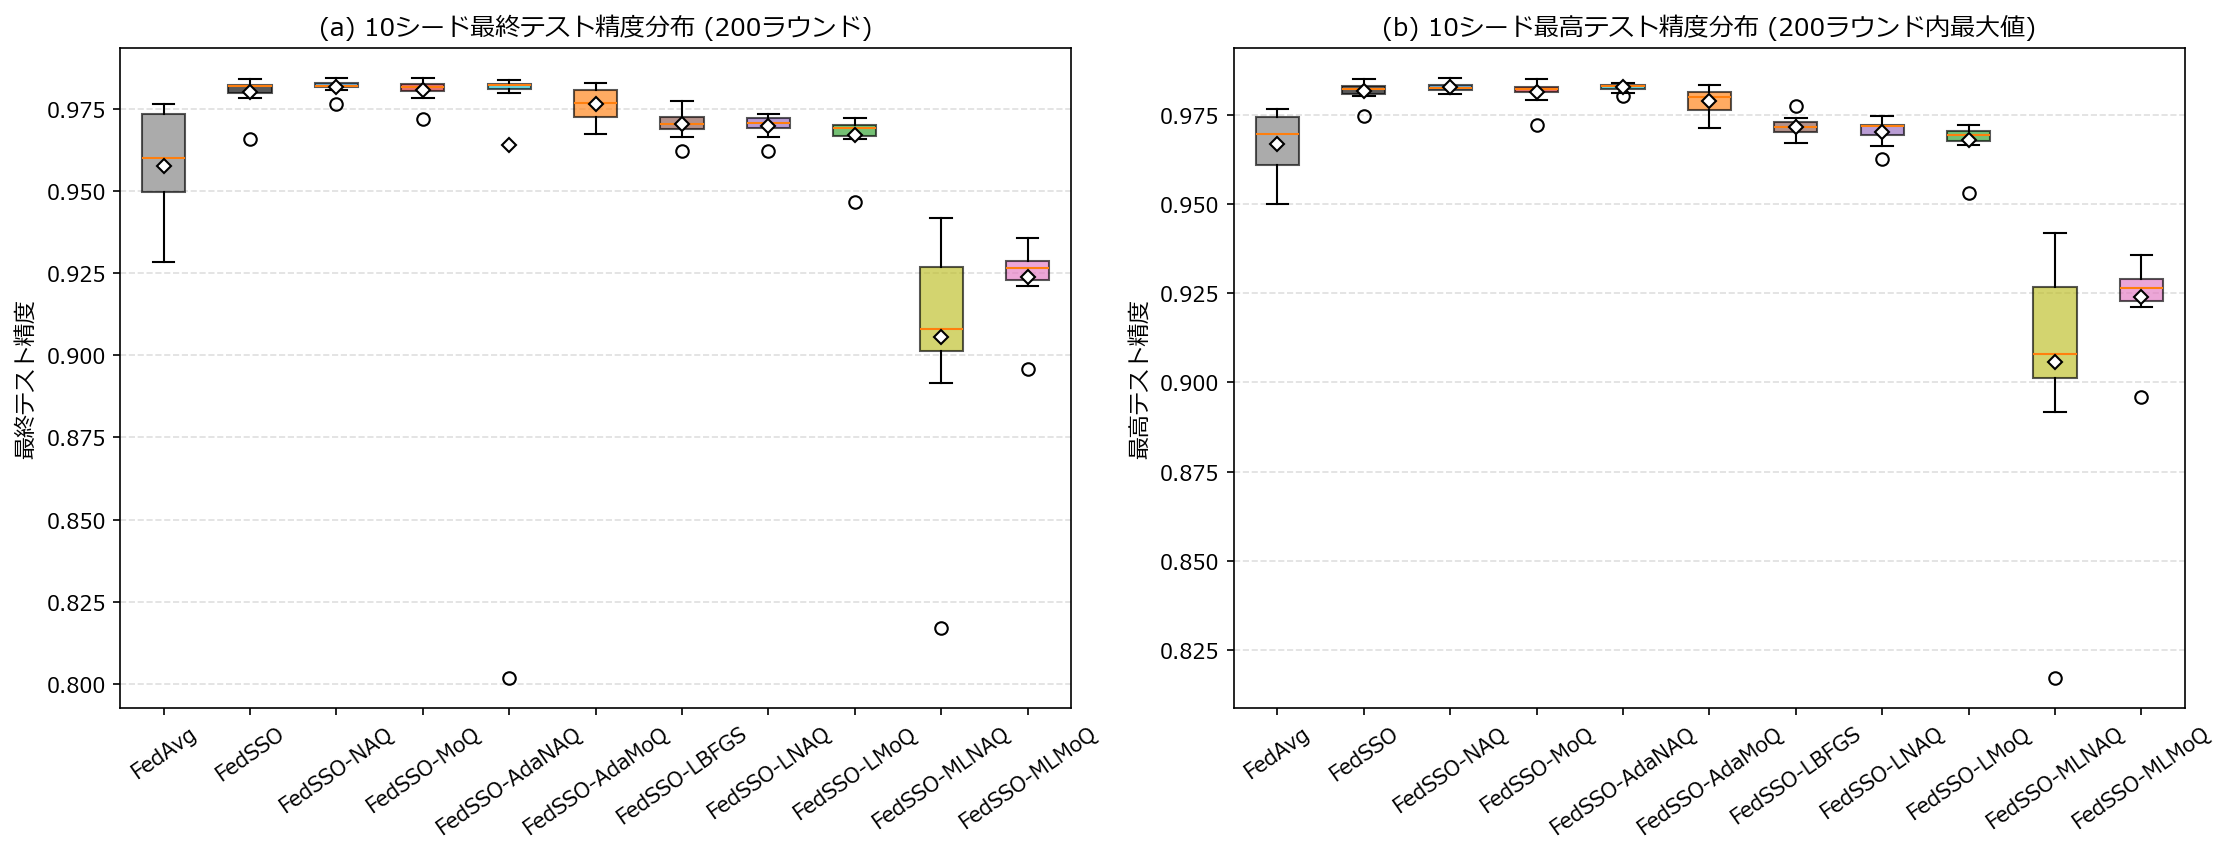

<cell-7>:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
<cell-7>:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


In [7]:
# 図3: 10シードにわたる最終テスト精度と最高テスト精度の分布 (Ave / Best / Worst)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
algos = list(summary_df["Algorithm"])
acc_groups = [per_seed_df[per_seed_df["Algorithm"] == a]["Final_Acc"].values for a in algos]
max_groups = [per_seed_df[per_seed_df["Algorithm"] == a]["Max_Acc"].values for a in algos]

bp1 = axes[0].boxplot(acc_groups, labels=algos, patch_artist=True, showmeans=True,
                      meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
for patch, a in zip(bp1["boxes"], algos):
    patch.set_facecolor(color_map[a])
    patch.set_alpha(0.65)
axes[0].set_title("(a) 10シード最終テスト精度分布 (200ラウンド)", fontsize=12)
axes[0].set_ylabel("最終テスト精度", fontsize=11)
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

bp2 = axes[1].boxplot(max_groups, labels=algos, patch_artist=True, showmeans=True,
                      meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
for patch, a in zip(bp2["boxes"], algos):
    patch.set_facecolor(color_map[a])
    patch.set_alpha(0.65)
axes[1].set_title("(b) 10シード最高テスト精度分布 (200ラウンド内最大値)", fontsize=12)
axes[1].set_ylabel("最高テスト精度", fontsize=11)
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("../report/img/ex002_cnn_seed_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 特定のシード値・アルゴリズムに絞ったグラフ表示

実験で自動保存されたシード別・アルゴリズム別の全ラウンド推移 CSV（`../datasets/ex002_cnn_history.csv` および `../datasets/ex002_cnn_logs/{Algorithm}_seed{Seed}.csv`）を読み込み、任意のアルゴリズム・シード値だけを指定して学習曲線を再描画できます。

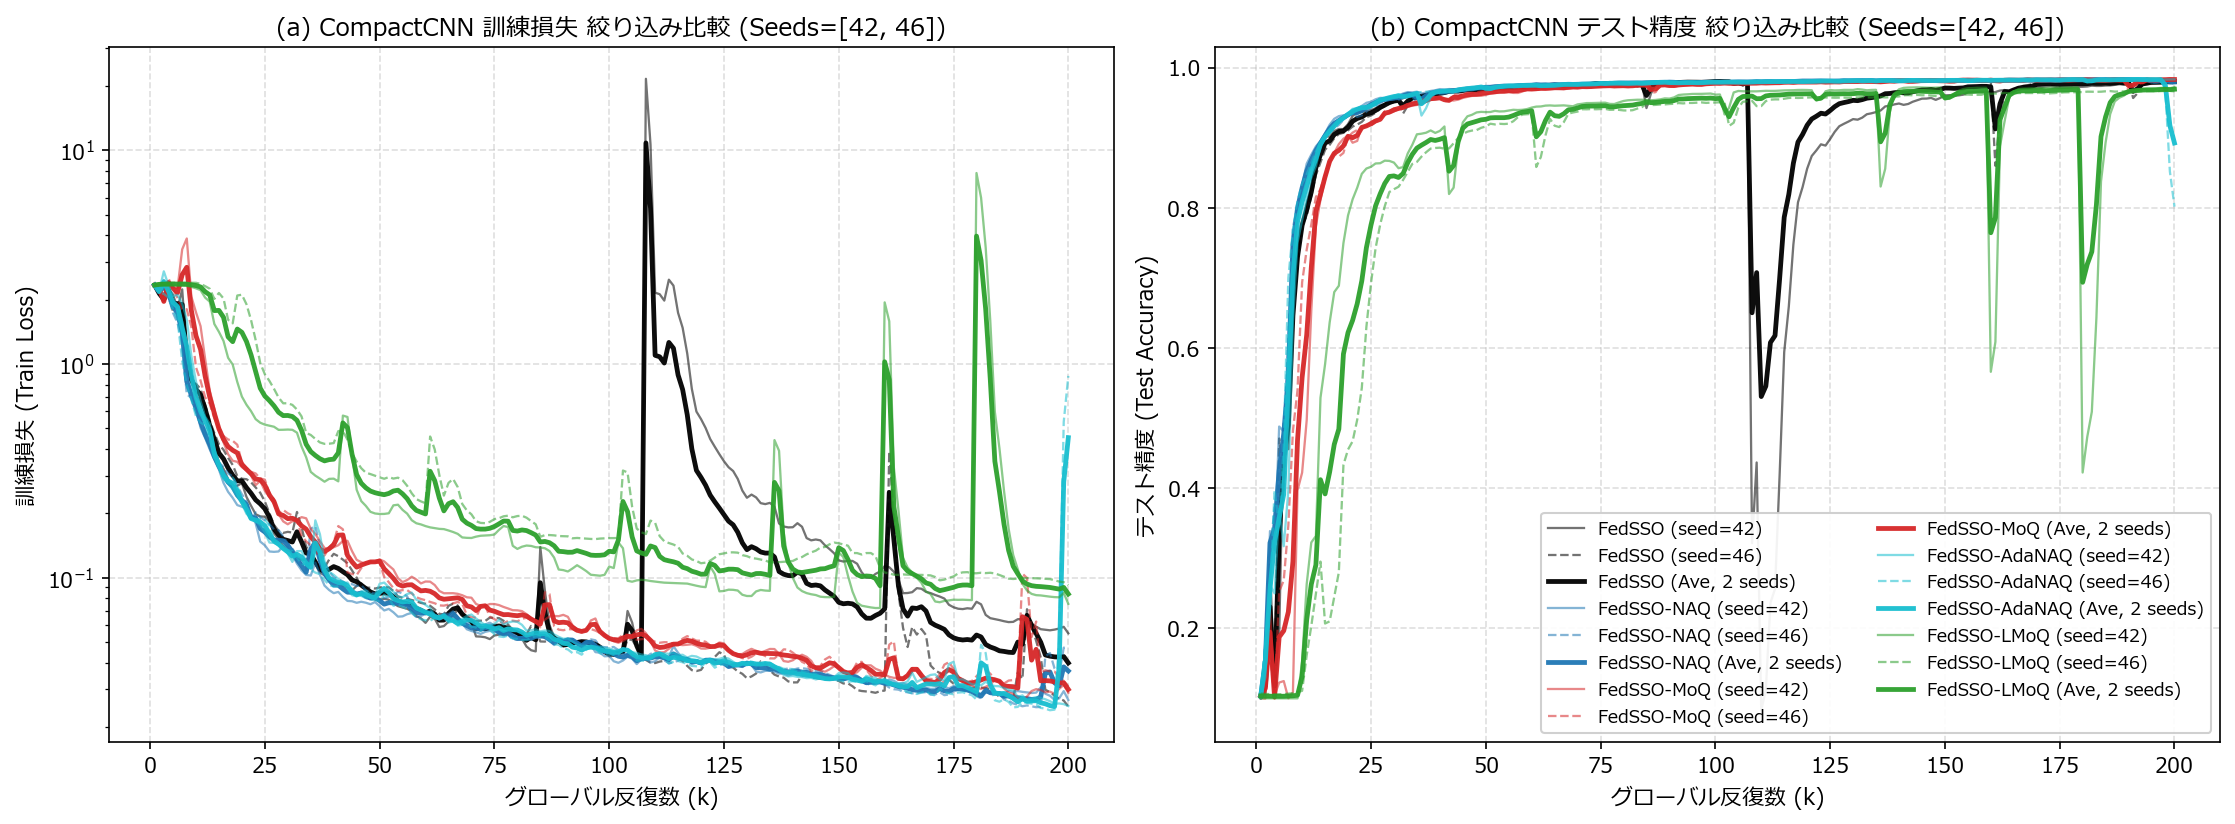

,Algorithm,Seed,Round,Comm_Round,Train_Loss,Test_Acc
0,FedSSO,42,200,200,0.054818,0.978181
1,FedSSO,46,200,200,0.024888,0.982065
2,FedSSO-AdaNAQ,42,200,399,0.025053,0.983208
3,FedSSO-AdaNAQ,46,200,399,0.878265,0.801634
4,FedSSO-LMoQ,42,200,200,0.075330,0.972127
5,FedSSO-LMoQ,46,200,200,0.092211,0.966130
6,FedSSO-MoQ,42,200,200,0.028910,0.982751
7,FedSSO-MoQ,46,200,200,0.031020,0.983265
8,FedSSO-NAQ,42,200,399,0.026741,0.982751
9,FedSSO-NAQ,46,200,399,0.046347,0.976525


In [8]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-LMoQ"]
SELECTED_SEEDS = [42, 46]   # 例: [46] にすると AdaNAQ のシード46 の終盤スパイクを確認可能
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか

filtered_ex2_df = plot_filtered_cnn_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    history_csv_path="../datasets/ex002_cnn_history.csv",
    log_dir="../datasets/ex002_cnn_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
)
filtered_ex2_df